# **The Unit Commitment Problem**

Packages need for this section of the project.

In [14]:
import pandas as pd
import numpy as np
from pandas import DataFrame, Series
import matplotlib.pyplot as plt
plt.style.use("default")
import gurobipy as gp
from gurobipy import GRB

The following **data** is used for the problem.

In [15]:
suppliers = ["Unit 1", "Unit 2", "Unit 3", "Unit 4", "Unit 5", "Unit 6", "Unit 7", "Unit 8", "Unit 9", "Unit 10"]


raw_unit_data = {
        "energy": ["coal", "coal", "natural gas", "natural gas", "natural gas", "natural gas", "wind", "wind", "solar", "solar"],
        "initial" : [400, 350, 205, 52, 155, 150, 78, 76, 0, 0],
        "initial_up_time" : [6, 5, 3, 1, 2, 2, 1, 1, 0, 0],
        "initial_down_time" : [0, 0, 0, 0, 0, 0, 0, 0, 1, 1],
        "min_gen": [100, 140, 78, 52, 54.25, 39, 17.4, 15.2, 4, 2.4],
        "max_gen": [425, 365, 220, 210, 165, 158, 90, 87, 20, 12],
        "min_uptime": [15, 15, 6, 5, 5, 4, 3, 3, 1, 1],
        "min_downtime":[9, 8, 7, 4, 3, 2, 2, 2, 1, 1],
        "ramp_up":   [212, 150, 101.2, 94.8, 58, 50, 40, 60, 20, 12],
        "ramp_down": [183, 198, 95.6, 101.7, 77.5, 60, 24, 45, 20, 12],
        "start_cost": [5000, 4550, 1320, 1291, 1280, 1105, 560, 554, 300, 250],
        "fixed_cost": [208.61, 117.37, 174.12, 172.75, 95.353, 144.52, 54.417, 54.551, 79.638, 16.259],
        "variable_cost": [22.536, 31.985, 70.5, 69, 32.146, 54.84, 40.222, 40.522, 116.33, 76.642]
}

df_units = DataFrame(raw_unit_data, index=suppliers)

initial_u = {i: int(df_units.loc[i, "initial"] > 0) for i in suppliers}

df_units

,energy,initial,initial_up_time,initial_down_time,min_gen,max_gen,min_uptime,min_downtime,ramp_up,ramp_down,start_cost,fixed_cost,variable_cost
Unit 1,coal,400,6,0,100,425,15,9,212,183,5000,209,23
Unit 2,coal,350,5,0,140,365,15,8,150,198,4550,117,32
Unit 3,natural gas,205,3,0,78,220,6,7,101,96,1320,174,70
Unit 4,natural gas,52,1,0,52,210,5,4,95,102,1291,173,69
Unit 5,natural gas,155,2,0,54,165,5,3,58,78,1280,95,32
Unit 6,natural gas,150,2,0,39,158,4,2,50,60,1105,145,55
Unit 7,wind,78,1,0,17,90,3,2,40,24,560,54,40
Unit 8,wind,76,1,0,15,87,3,2,60,45,554,55,41
Unit 9,solar,0,0,1,4,20,1,1,20,20,300,80,116
Unit 10,solar,0,0,1,2,12,1,1,12,12,250,16,77


In [16]:
raw_demand = [872,861,869,896,947,1028,1128,1226,1321,1387,1427,1440,1433,1437,1437,1431,1411,1366,1302,1238,1184,1117,1043,981,
898,879,881,905,954,1035,1138,1234,1324,1390,1433,1440,1432,1434,1432,1422,1404,1360,1295,1228,1167,1093,1012,945,
899,879,881,905,954,1036,1138,1233,1324,1390,1433,1441,1433,1435,1433,1423,1405,1362,1296,1229,1168,1094,1014,946,
899,880,883,906,956,1037,1140,1235,1326,1393,1436,1443,1435,1437,1435,1425,1407,1363,1298,1230,1170,1096,1015,948,
910,890,892,919,969,1048,1151,1243,1333,1401,1443,1448,1437,1439,1434,1422,1408,1360,1291,1218,1157,1079,998,932,
825,804,807,834,877,921,950,992,1040,1076,1098,1102,1097,1098,1097,1091,1082,1059,1017,968,937,916,843,761,
691,656,643,656,684,729,785,837,895,943,973,988,994,998,1000,1000,996,974,927,869,814,760,704,659]

reserve = [1,1,1,1,1,1,1,1,1,1,1,1,
           1,1,1,1,1,1,1,1,1,1,1,1,
           1,1,1,1,1,1,1,1,1,1,1,1,
           1,1,1,1,1,1,1,1,1,1,1,1,
           1,1,1,1,1,1,1,1,1,1,1,1,
           1,1,1,1,1,1,1,1,1,1,1,1,
           1,1,1,1,1,1,1,1,1,1,1,1,
           1,1,1,1,1,1,1,1,1,1,1,1,
           1,1,1,1,1,1,1,1,1,1,1,1,
           1,1,1,1,1,1,1,1,1,1,1,1,
           1,1,1,1,1,1,1,1,1,1,1,1,
           1,1,1,1,1,1,1,1,1,1,1,1,
           1,1,1,1,1,1,1,1,1,1,1,1,
           1,1,1,1,1,1,1,1,1,1,1,1]

# from load_excel_data import load_case_study

# suppliers, raw_unit_data, raw_demand = load_case_study("/Users/vanessahagelskjaer/Downloads/100 unit case study data.xlsx", n_units=50)

# raw_demand = [x * 0.8 for x in raw_demand]

periods = len(raw_demand)
time = range(periods)

demand = Series(raw_demand, index = range(1, periods+1))

df_units = DataFrame(raw_unit_data, index=suppliers)

initial_u = {i: int(df_units.loc[i, "initial"] > 0) for i in suppliers}

df_units


,energy,initial,initial_up_time,initial_down_time,min_gen,max_gen,min_uptime,min_downtime,ramp_up,ramp_down,start_cost,fixed_cost,variable_cost
Unit 1,coal,400,6,0,100,425,15,9,212,183,5000,209,23
Unit 2,coal,350,5,0,140,365,15,8,150,198,4550,117,32
Unit 3,natural gas,205,3,0,78,220,6,7,101,96,1320,174,70
Unit 4,natural gas,52,1,0,52,210,5,4,95,102,1291,173,69
Unit 5,natural gas,155,2,0,54,165,5,3,58,78,1280,95,32
Unit 6,natural gas,150,2,0,39,158,4,2,50,60,1105,145,55
Unit 7,wind,78,1,0,17,90,3,2,40,24,560,54,40
Unit 8,wind,76,1,0,15,87,3,2,60,45,554,55,41
Unit 9,solar,0,0,1,4,20,1,1,20,20,300,80,116
Unit 10,solar,0,0,1,2,12,1,1,12,12,250,16,77


Next up the problem is defined.

In [17]:
model = gp.Model("production")

The **variables** are added.

In [18]:
u = model.addVars(suppliers, time, vtype=GRB.BINARY, name="u")
y = model.addVars(suppliers, time, vtype=GRB.BINARY, name="y")
z = model.addVars(suppliers, time, vtype=GRB.BINARY, name="z")

q = model.addVars(suppliers, time, vtype=GRB.CONTINUOUS, lb=0, name="q")

The **constraints** are added.

In [19]:
model.addConstrs((gp.quicksum(q[i,t] for i in suppliers) == raw_demand[t] for t in time), name="Market clearing")

model.addConstrs(df_units.loc[i, "min_gen"] * u[i, t] <= q[i,t] for i in suppliers for t in time)
model.addConstrs(df_units.loc[i, "max_gen"] * u[i, t] >= q[i,t] for i in suppliers for t in time)

model.addConstrs(gp.quicksum(df_units.loc[i, "max_gen"] * u[i, t] for i in suppliers) >= reserve[t] * raw_demand[t] for t in time)

model.addConstrs(q[i, t] - q[i, t-1] <= df_units.loc[i, "ramp_up"] for i in suppliers for t in range(1, periods))

model.addConstrs(q[i, t-1] - q[i, t] <= df_units.loc[i, "ramp_down"] for i in suppliers for t in range(1, periods))

model.addConstrs((gp.quicksum(u[i, tau] for tau in range(t, t + int(df_units.loc[i, "min_uptime"]))) >= df_units.loc[i, "min_uptime"] * y[i, t] for i in suppliers
                  for t in range(periods - int(df_units.loc[i, "min_uptime"]) + 1)), name="Minimum up time")

model.addConstrs((gp.quicksum((1 - u[i, tau]) for tau in range(t, t + int(df_units.loc[i, "min_downtime"]))) >= df_units.loc[i, "min_downtime"] * z[i, t] for i in
                  suppliers for t in range(periods - int(df_units.loc[i, "min_downtime"]) + 1)), name="Minimum down time")

model.addConstrs(u[i, t] - u[i, t-1] == y[i,t] - z[i,t] for i in suppliers for t in range(1, periods))

model.addConstrs((u[i, 0] - initial_u[i] == y[i, 0] - z[i, 0] for i in suppliers), name="Initial commitment")

model.addConstrs((q[i, 0] - df_units.loc[i, "initial"] <= df_units.loc[i, "ramp_up"] for i in suppliers), name="Initial ramp up")

model.addConstrs((df_units.loc[i, "initial"] - q[i, 0] <= df_units.loc[i, "ramp_down"] for i in suppliers), name="Initial ramp down")

for i in suppliers:
    min_up = int(df_units.loc[i, "min_uptime"])
    min_down = int(df_units.loc[i, "min_downtime"])

    initial = df_units.loc[i, "initial"]
    initial_up = int(df_units.loc[i, "initial_up_time"])
    initial_down = int(df_units.loc[i, "initial_down_time"])

    if initial > 0:
        remaining_up = min_up - initial_up
        for t in range(remaining_up):
            model.addConstr(u[i, t] == 1, name=f"Initial minimum up time_{i}_{t}")
    else:
        remaining_down = min_down - initial_down
        for t in range(remaining_down):
            model.addConstr(u[i, t] == 0, name=f"Initial minimum down time_{i}_{t}")

Set **the objective function** and solve the problem.

In [20]:
model.setObjective(gp.quicksum(df_units.loc[i, "variable_cost"] * q[i, t] + df_units.loc[i, "fixed_cost"] * u[i, t] + df_units.loc[i, "start_cost"] * y[i, t] for i
                               in suppliers for t in time), GRB.MINIMIZE)
model.Params.MIPGap = 0
model.optimize()

Set parameter MIPGap to value 0
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 25.6.0 25G72)

CPU model: Apple M2
Thread count: 8 physical cores, 8 logical processors, using up to 8 threads

Non-default parameters:
MIPGap  0

Optimize a model with 12054 rows, 6720 columns and 42396 nonzeros (Min)
Model fingerprint: 0x399c1917
Model has 5040 linear objective coefficients
Variable types: 1680 continuous, 5040 integer (5040 binary)
Coefficient statistics:
  Matrix range     [1e+00, 4e+02]
  Objective range  [2e+01, 5e+03]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+03]

Presolve removed 2199 rows and 897 columns
Presolve time: 0.12s
Presolved: 9855 rows, 5823 columns, 36502 nonzeros
Variable types: 1678 continuous, 4145 integer (4145 binary)
Found heuristic solution: objective 6994925.0323
Found heuristic solution: objective 6817980.8494

Root relaxation: objective 6.055032e+06, 2774 iterations, 0.03 seconds (0.04 work units)

    Nodes    |    C

Following shows the results of the model above.

In [21]:
if model.status == GRB.OPTIMAL:

    print("Optimal solution found!")
    print("Total cost:", model.objVal)

    # Store results
    results = []

    for i in suppliers:
        for t in time:
            results.append({
                "unit": i,
                "time": t,
                "generation": q[i,t].X,
                "status": round(u[i,t].X),
                "startup": round(y[i,t].X),
                "shutdown": round(z[i,t].X)
            })

    results_df = pd.DataFrame(results)

    print(results_df)

else:
    print("No optimal solution found.")

Optimal solution found!
Total cost: 6062386.357699992
         unit  time  generation  status  startup  shutdown
0      Unit 1     0         306       1        0         0
1      Unit 1     1         425       1        0         0
2      Unit 1     2         425       1        0         0
3      Unit 1     3         425       1        0         0
4      Unit 1     4         425       1        0         0
...       ...   ...         ...     ...      ...       ...
1675  Unit 10   163           0       0        0         0
1676  Unit 10   164           0       0        0         0
1677  Unit 10   165           0       0        0         0
1678  Unit 10   166           0       0        0         0
1679  Unit 10   167           0       0        0         0

[1680 rows x 6 columns]


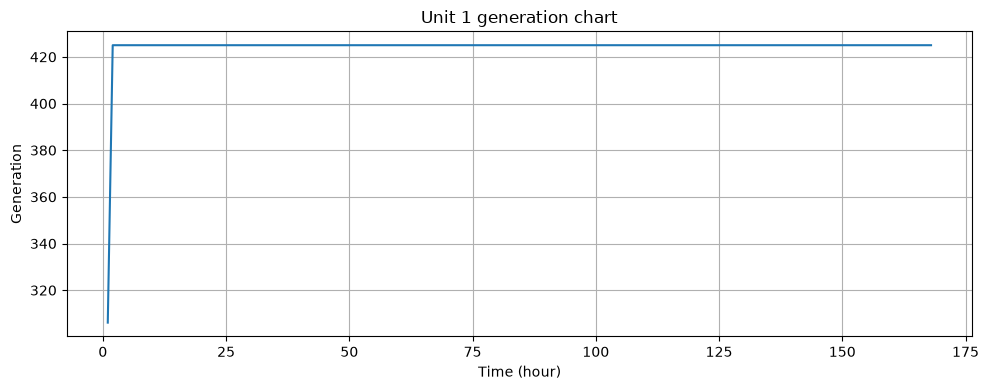

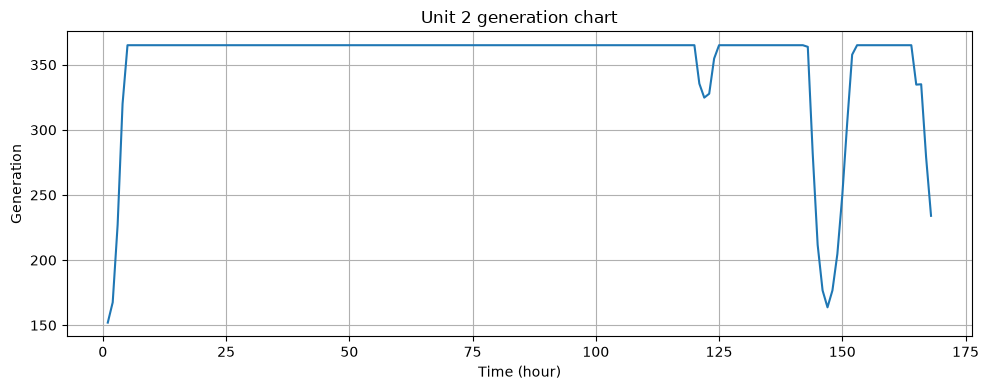

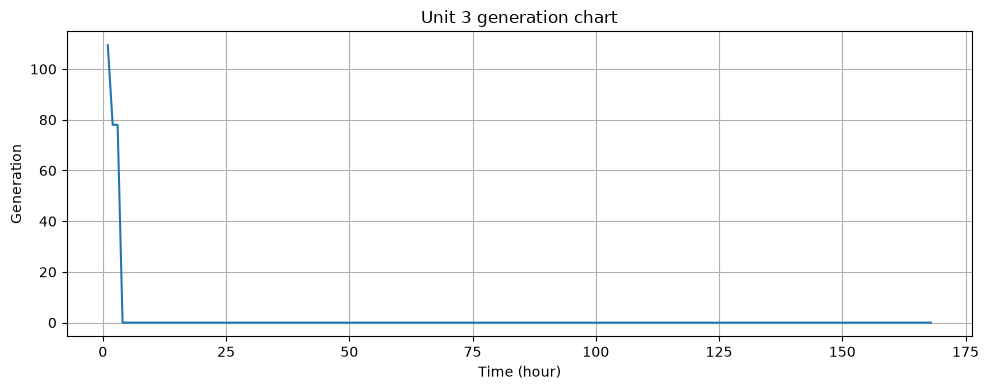

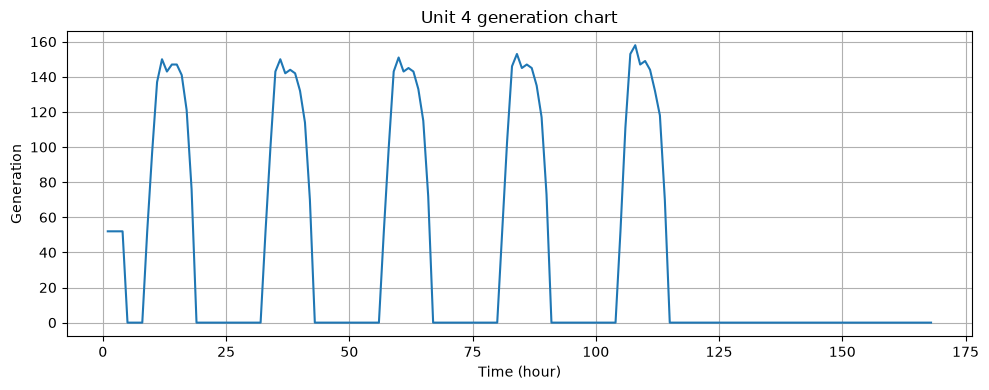

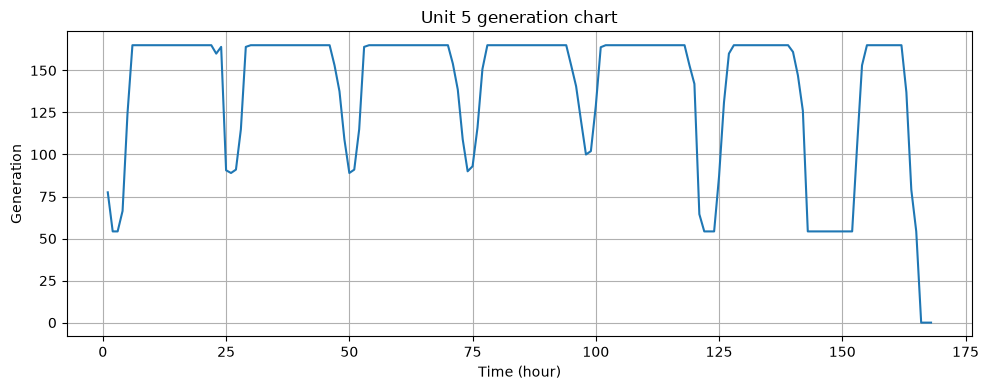

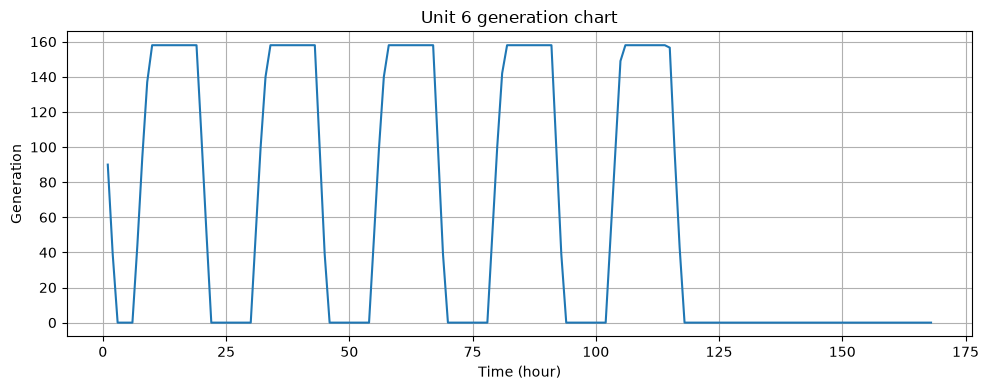

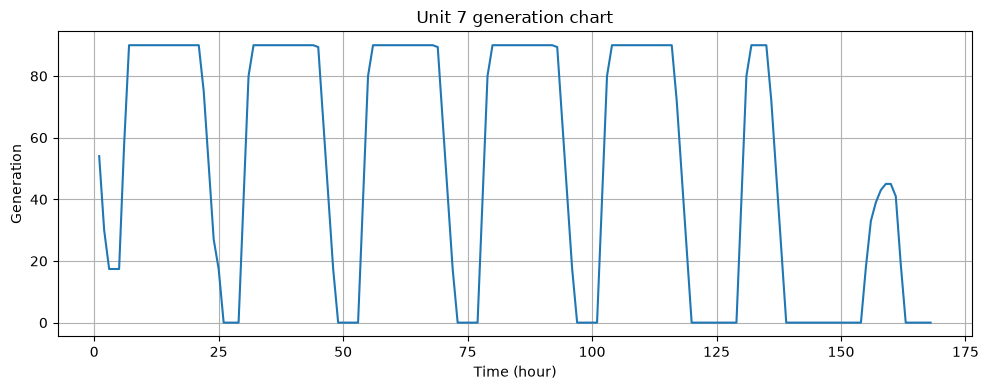

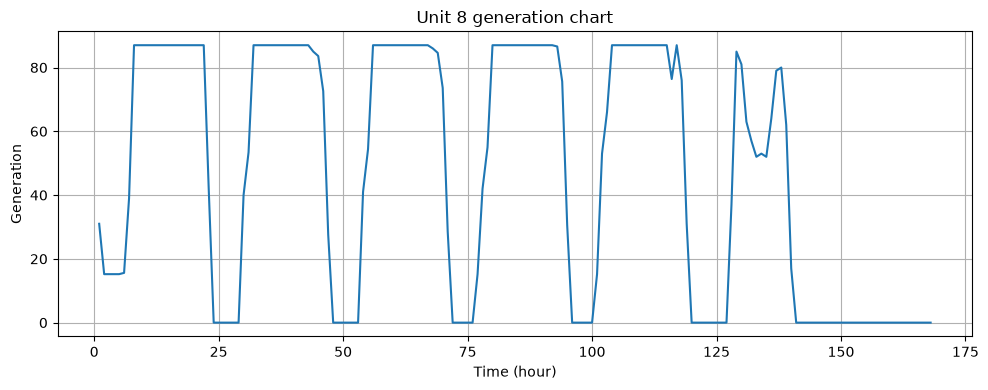

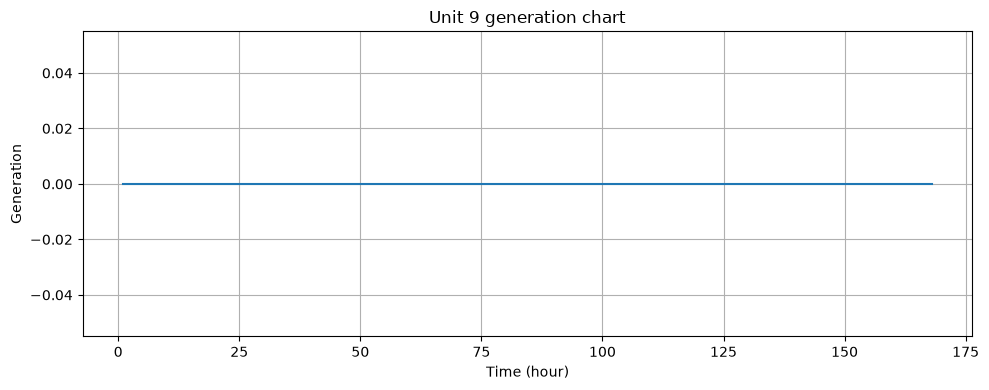

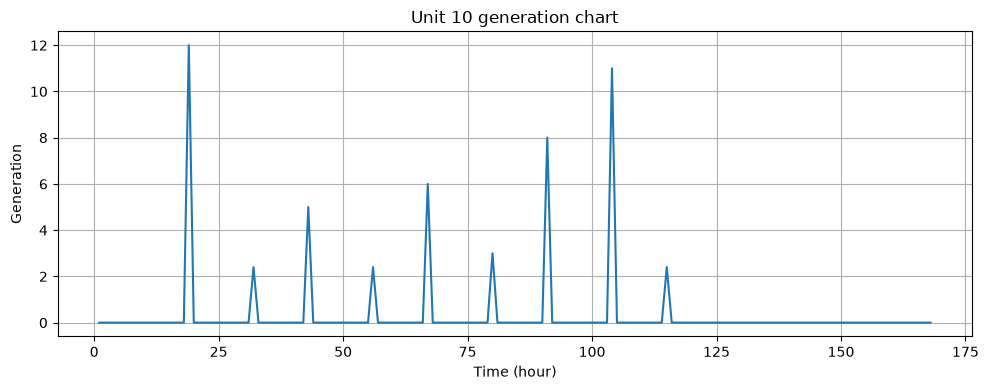

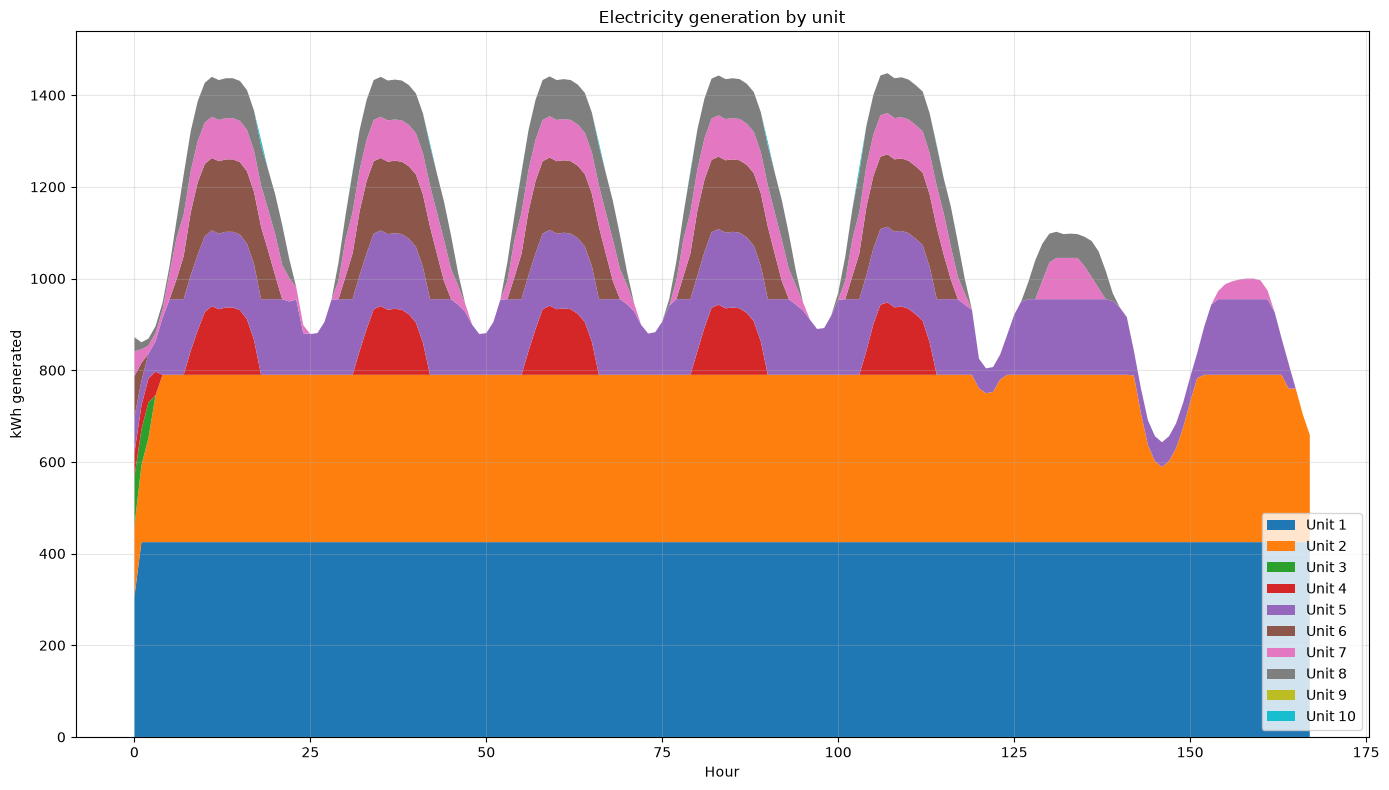

In [22]:
for i in suppliers:
    supplier_data = results_df[results_df["unit"] == i]

    plt.figure(figsize=(10, 4))

    plt.plot(
        supplier_data["time"] + 1,
        supplier_data["generation"]
    )

    plt.title(f"{i} generation chart")
    plt.xlabel("Time (hour)")
    plt.ylabel("Generation")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

generation_df = results_df.pivot(
    index="time",
    columns="unit",
    values="generation"
)

initial_generation = {
    "Unit 1": 400,
    "Unit 2": 350,
    "Unit 3": 205,
    "Unit 4": 52,
    "Unit 5": 155,
    "Unit 6": 150,
    "Unit 7": 78,
    "Unit 8": 76,
    "Unit 9": 0,
    "Unit 10": 0}

initial_row = pd.DataFrame(
    [initial_generation],
    index=[0]
)

generation_df = pd.concat([initial_row, generation_df])
generation_df = generation_df.sort_index()

plt.figure(figsize=(14, 8))

plt.stackplot(
    generation_df.index,
    generation_df.T,
    labels=generation_df.columns
)

plt.title("Electricity generation by unit")
plt.xlabel("Hour")
plt.ylabel("kWh generated")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)


plt.tight_layout()
plt.savefig("Generation chart.png")
plt.show()

Fix the binary results from the UC problem.

In [23]:
u_sol = {(i, t): round(u[i, t].X) for i in suppliers for t in time}
y_sol = {(i, t): round(y[i, t].X) for i in suppliers for t in time}
z_sol = {(i, t): round(z[i, t].X) for i in suppliers for t in time}

Define the new model need for finding the hourly prices.

In [24]:
price_model = gp.Model("price")

q_price = price_model.addVars(suppliers, time, lb=0, vtype=GRB.CONTINUOUS, name="q")

market_clearing = price_model.addConstrs((gp.quicksum(q_price[i,t] for i in suppliers) == raw_demand[t] for t in time), name="Market clearing")

price_model.addConstrs((q_price[i, t] >= df_units.loc[i, "min_gen"] * u_sol[i, t] for i in suppliers for t in time), name="Minimum generation")
price_model.addConstrs((q_price[i, t] <= df_units.loc[i, "max_gen"] * u_sol[i, t] for i in suppliers for t in time), name="Maximum generation")

price_model.addConstrs(gp.quicksum(df_units.loc[i, "max_gen"] * u_sol[i, t] for i in suppliers) >= reserve[t] * raw_demand[t] for t in time)

price_model.addConstrs((q_price[i, t] - q_price[i, t-1] <= df_units.loc[i, "ramp_up"] for i in suppliers for t in range(1, periods)), name="Ramp up")

price_model.addConstrs((q_price[i, t-1] - q_price[i, t] <= df_units.loc[i, "ramp_down"] for i in suppliers for t in range(1, periods)), name="Ramp down")

price_model.addConstrs((q_price[i, 0] - df_units.loc[i, "initial"] <= df_units.loc[i, "ramp_up"] for i in suppliers), name="Initial ramp up")

price_model.addConstrs((df_units.loc[i, "initial"] - q_price[i, 0] <= df_units.loc[i, "ramp_down"] for i in suppliers), name="Initial ramp down")

price_model.setObjective(gp.quicksum(df_units.loc[i, "variable_cost"] * q_price[i, t] + df_units.loc[i, "fixed_cost"] * u_sol[i, t] + df_units.loc[i, "start_cost"] *
                                     y_sol[i, t] for i in suppliers for t in time), GRB.MINIMIZE)

price_model.optimize()

Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 25.6.0 25G72)

CPU model: Apple M2
Thread count: 8 physical cores, 8 logical processors, using up to 8 threads

Optimize a model with 7056 rows, 1680 columns and 11740 nonzeros (Min)
Model fingerprint: 0xe1f1a016
Model has 1680 linear objective coefficients and an objective constant of 1.2435051500000224e+05
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [2e+01, 1e+02]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+03]

Presolve removed 6690 rows and 1288 columns
Presolve time: 0.00s
Presolved: 366 rows, 559 columns, 1178 nonzeros

Iteration    Objective       Primal Inf.    Dual Inf.      Time
       0    5.9602514e+06   1.955702e+03   0.000000e+00      0s
     113    6.0623864e+06   0.000000e+00   0.000000e+00      0s

Solved in 113 iterations and 0.01 seconds (0.01 work units)
Optimal objective  6.062386358e+06


Then the price is found.

Optimal fixed-commitment LP found.
Variable generation cost: 6062386.35769999


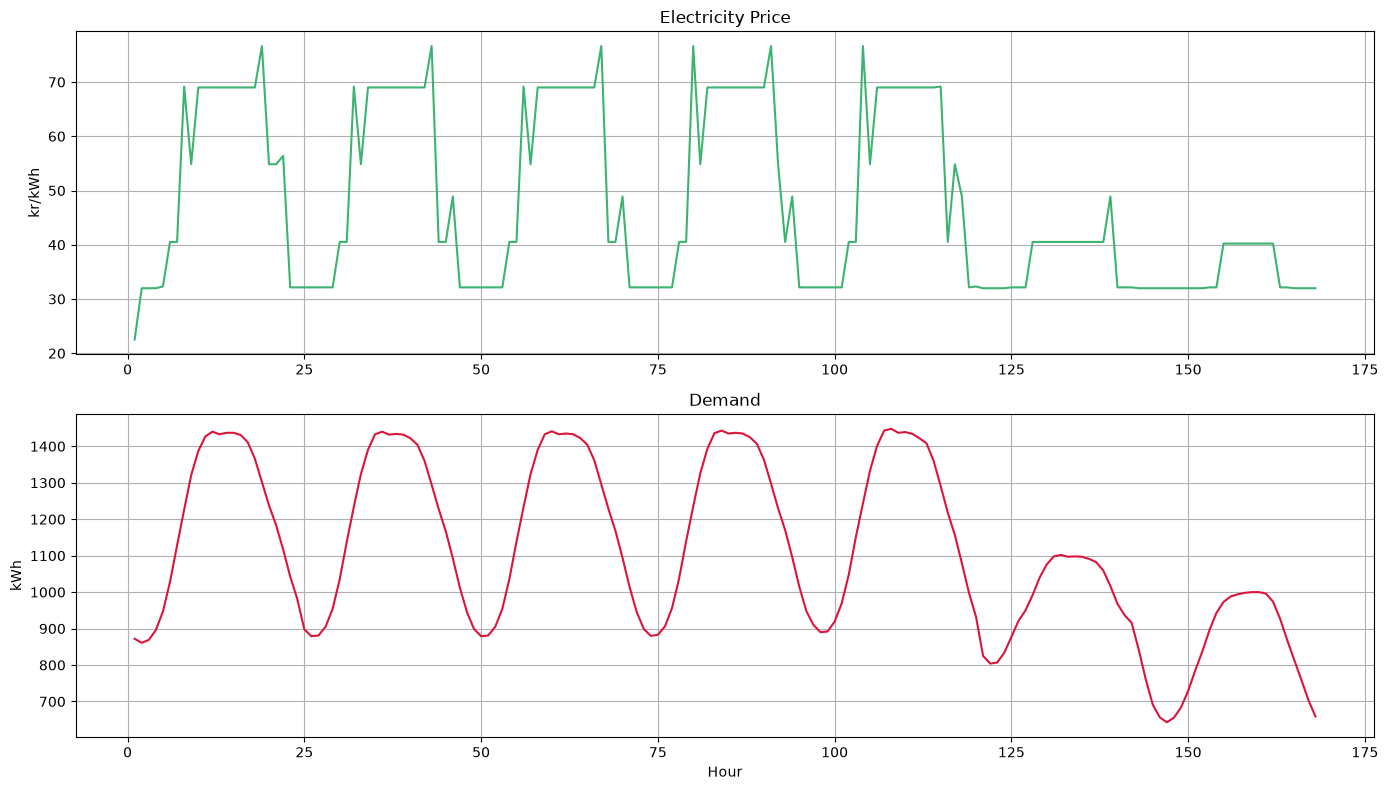

     time  demand  price
0       0     872     23
1       1     861     32
2       2     869     32
3       3     896     32
4       4     947     32
..    ...     ...    ...
163   163     869     32
164   164     814     32
165   165     760     32
166   166     704     32
167   167     659     32

[168 rows x 3 columns]


In [25]:
if price_model.status == GRB.OPTIMAL:

    print("Optimal fixed-commitment LP found.")
    print("Variable generation cost:", price_model.objVal)

else:

    print("The LP did not find an optimal solution.")
    print("Gurobi status:", price_model.status)

if price_model.status == GRB.OPTIMAL:

    prices = []

    for t in time:

        prices.append({
            "time": t,
            "demand": raw_demand[t],
            "price": market_clearing[t].Pi
        })


    price_df = pd.DataFrame(prices)

    fig, axes = plt.subplots(2, 1, figsize=(14, 8))

    axes[0].plot(price_df["time"] + 1, price_df["price"], color="mediumseagreen")
    axes[0].set_title("Electricity Price")
    axes[0].set_ylabel("kr/kWh")
    axes[0].grid(True)

    axes[1].plot(price_df["time"] + 1, price_df["demand"], color="crimson")
    axes[1].set_title("Demand")
    axes[1].set_ylabel("kWh")
    axes[1].set_xlabel("Hour")
    axes[1].grid(True)

    plt.tight_layout()
    plt.savefig("Price_demand.png")
    plt.show()

    print(price_df)


In [26]:
u_values = {(i, t): u[i, t].X for i in suppliers for t in time}
y_values = {(i, t): y[i, t].X for i in suppliers for t in time}
z_values = {(i, t): z[i, t].X for i in suppliers for t in time}
q_values = {(i, t): q[i, t].X for i in suppliers for t in time}

revenue = {}
cost = {}
uplift = {}
profit = {}

for i in suppliers:

    revenue[i] = sum(
        market_clearing[t].Pi * q_values[i, t]
        for t in time
    )

    cost[i] = sum(
        df_units.loc[i, "variable_cost"] * q_values[i, t]
        + df_units.loc[i, "fixed_cost"] * u_values[i, t]
        + df_units.loc[i, "start_cost"] * y_values[i, t]
        for t in time
    )

    profit[i] = revenue[i] - cost[i]

pd.set_option("display.float_format", "{:,.0f}".format)

profit_df = pd.DataFrame([
    {
        "Unit": i,
        "revenue": revenue[i],
        "cost": cost[i],
        "profit": profit[i],
    }
    for i in suppliers
])

print(profit_df.to_string(float_format=lambda x: f"{x:.2f}"))

      Unit    revenue       cost     profit
0   Unit 1 3424650.94 1641437.35 1783213.60
1   Unit 2 2876867.27 1912420.94  964446.33
2   Unit 3    7455.10   19233.06  -11777.96
3   Unit 4  419722.93  447378.50  -27655.57
4   Unit 5 1199358.24  774340.27  425017.97
5   Unit 6  670306.03  574847.46   95458.57
6   Unit 7  502597.28  354260.40  148336.88
7   Unit 8  476408.64  332071.33  144337.30
8   Unit 9       0.00       0.00       0.00
9  Unit 10    3946.83    6397.04   -2450.22
